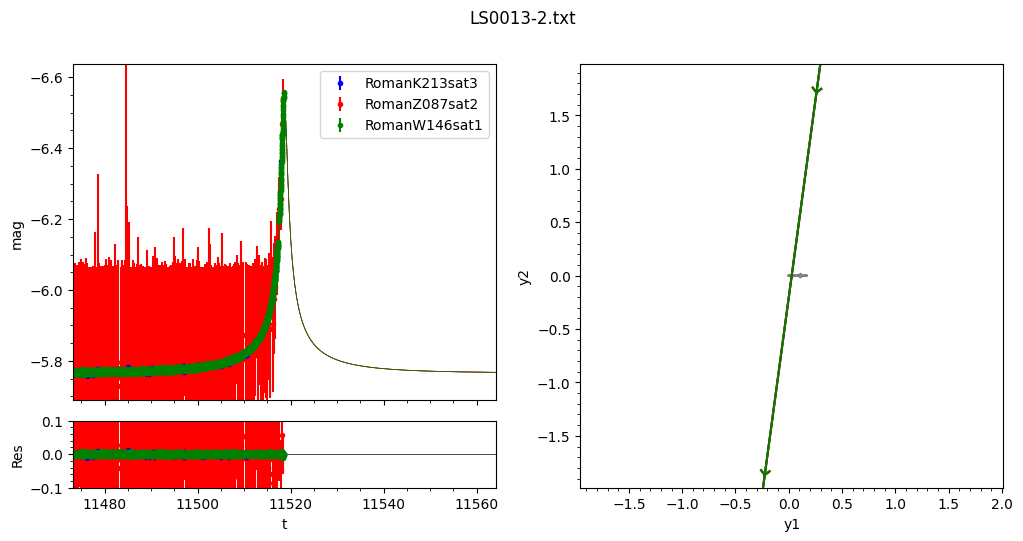

╒════════╤══════════════════════╕
│ chi2   │ 49908.67639334206    │
╞════════╪══════════════════════╡
│ s      │ 1.0560 +- 0.0029     │
├────────┼──────────────────────┤
│ q      │ 0.000174 +- 0.000015 │
├────────┼──────────────────────┤
│ u0     │ 0.02696 +- 0.00013   │
├────────┼──────────────────────┤
│ alpha  │ 1.436 +- 0.015       │
├────────┼──────────────────────┤
│ rho    │ 0.00943 +- 0.00038   │
├────────┼──────────────────────┤
│ tE     │ 22.724 +- 0.100      │
├────────┼──────────────────────┤
│ t0     │ 11518.6408 +- 0.0028 │
╘════════╧══════════════════════╛

╒═══════════════╤═════════════════════════╤════════════════╕
│ telescope     │ baseline                │ blending       │
╞═══════════════╪═════════════════════════╪════════════════╡
│ RomanK213sat3 │ -5.7658533 +- 0.0000036 │ 33.36 +- 0.20  │
├───────────────┼─────────────────────────┼────────────────┤
│ RomanZ087sat2 │ 0.167033 +- 0.000017    │ 6.651 +- 0.046 │
├───────────────┼─────────────────────────┼────────────

In [1]:
import numpy as np
import pandas as pd
import glob
import RTModel.plotmodel as plm
import matplotlib.pyplot as plt
from scipy.optimize import lsq_linear

event_data_me = 'event_data_chris'
root_dir = '/home/mldc-ipacpeople-admin/teams/mldc-ipacpeople/'
eventnumber = '306462' # '306575' '306569' '306543' "! Ephemerides table not available for this satellite!"
eventname = root_dir+event_data_me+'/event_'+eventnumber
models = glob.glob(eventname +'/FinalModels/*')
model = models[0] # let's plot the first of the best models

if model.removeprefix("/home/mldc-ipacpeople-admin/teams/mldc-ipacpeople/"+event_data_me+"/event_"+eventnumber+"/FinalModels/")[:2] == 'LS':
    myplot = plm.plotmodel(eventname = eventname, modelfile = model)
else:
    print("can't plot non-LS or PS models for some reason")

In [2]:
models

['/home/mldc-ipacpeople-admin/teams/mldc-ipacpeople/event_data_chris/event_306462/FinalModels/LS0013-2.txt',
 '/home/mldc-ipacpeople-admin/teams/mldc-ipacpeople/event_data_chris/event_306462/FinalModels/BS0021-5.txt',
 '/home/mldc-ipacpeople-admin/teams/mldc-ipacpeople/event_data_chris/event_306462/FinalModels/LS0228-0.txt',
 '/home/mldc-ipacpeople-admin/teams/mldc-ipacpeople/event_data_chris/event_306462/FinalModels/LS0013-5.txt']

In [3]:
category_list = []
s_list = []
q_list = []
u0_list = []
alpha_list = []
rho_list = []
tE_list = []
t0_list = []
flux_bg_213_list = []
flux_source_213_list = []
flux_bg_146_list = []
flux_source_146_list = []
flux_bg_087_list = []
flux_source_087_list = []
t0_anomaly_list = []
y1_anomaly_list = []
y2_anomaly_list = []
delta_chisq_anomaly_list = []
delta_chisq_list = []
s_err_list = []
q_err_list = []
u0_err_list = []
alpha_err_list = []
rho_err_list = []
tE_err_list = []
t0_err_list = []
flux_bg_213_err_list = []
flux_source_213_err_list = []
flux_bg_146_err_list = []
flux_source_146_err_list = []
flux_bg_087_err_list = []
flux_source_087_err_list = []
for model in models:
    with open(model, 'r') as file:
        # read first line: parameters
        line = file.readline().split()
        print("line: ", line)
        category = model.removeprefix("/home/mldc-ipacpeople-admin/teams/mldc-ipacpeople/"+event_data_me+"/event_"+eventnumber+"/FinalModels/")[:2]
        category_list.append(category)
        s, q, u0, alpha, rho, tE, t0 = line[0], line[1], line[2], line[3], line[4], line[5], line[6]
        flux_bg_213, flux_source_213 = line[7], line[8]
        flux_bg_146, flux_source_146 = line[9], line[10]
        flux_bg_087, flux_source_087 = line[11], line[12]
        t0_anomaly, y1_anomaly, y2_anomaly, delta_chisq_anomaly = line[13], line[14], line[15], line[16]
        delta_chisq = line[17]
        s_list.append(s), q_list.append(q), u0_list.append(u0), alpha_list.append(alpha), rho_list.append(rho), tE_list.append(tE), t0_list.append(t0)
        flux_bg_213_list.append(flux_bg_213), flux_source_213_list.append(flux_source_213)
        flux_bg_146_list.append(flux_bg_146), flux_source_146_list.append(flux_source_146)
        flux_bg_087_list.append(flux_bg_087), flux_source_087_list.append(flux_source_087)
        t0_anomaly_list.append(t0_anomaly), y1_anomaly_list.append(y1_anomaly), y2_anomaly_list.append(y2_anomaly), delta_chisq_anomaly_list.append(delta_chisq_anomaly)
        delta_chisq_list.append(delta_chisq)
        
        # read second line: parameter uncertainties
        line = file.readline().split()
        s_err, q_err, u0_err, alpha_err, rho_err, tE_err, t0_err = line[0], line[1], line[2], line[3], line[4], line[5], line[6]
        flux_bg_213_err, flux_source_213_err = line[7], line[8]
        flux_bg_146_err, flux_source_146_err = line[9], line[10]
        flux_bg_087_err, flux_source_087_err = line[11], line[12]
        s_err_list.append(s_err), q_err_list.append(q_err), u0_err_list.append(u0_err), alpha_err_list.append(alpha_err), rho_err_list.append(rho_err), tE_err_list.append(tE_err), t0_err_list.append(t0_err)
        flux_bg_213_err_list.append(flux_bg_213_err), flux_source_213_err_list.append(flux_source_213_err)
        flux_bg_146_err_list.append(flux_bg_146_err), flux_source_146_err_list.append(flux_source_146_err)
        flux_bg_087_err_list.append(flux_bg_087_err), flux_source_087_err_list.append(flux_source_087_err)


line:  ['1.0560465502482783e+00', '1.7402559120476140e-04', '2.6957227870649195e-02', '1.4361556321305979e+00', '9.4338074029343497e-03', '2.2723934388714760e+01', '1.1518640831554896e+04', '1.965685e+02', '5.892472e+00', '7.453395e-01', '1.120667e-01', '1.756320e+01', '2.173646e+00', '1.1518171220000000e+04', '2.9487332707572353e-02', '1.6860325753328399e-02', '5.7722692222711942e+01', '4.9908676393342059e+04']
line:  ['2.1538795007180564e+01', '6.7972927875645117e-01', '6.4369067509234266e-05', '3.8152755331885085e-02', '1.1519326273780556e+04', '1.1518283637327182e+04', '4.4046495021101743e-02', '1.958489e+02', '6.614948e+00', '7.301544e-01', '1.271864e-01', '1.729433e+01', '2.443323e+00', '1.1518230243000000e+04', '5.0886355536178103e-02', '-6.4369067509234266e-05', '4.2142295923616331e+01', '4.9932178474491149e+04']
line:  ['1.0884009037644886e+00', '4.3811517931065784e-05', '2.6451929522389669e-02', '4.1111707499148036e+00', '2.0001653372913575e-03', '2.2092728632896886e+01', '1.

In [4]:
results = pd.DataFrame({'s': s_list, 's_err': s_err_list, 'q': q_list, 'q_err': q_err_list, 'u0': u0_list, 'u0_err': u0_err_list, 
                        'alpha': alpha_list, 'alpha_err': alpha_err_list, 'rho': rho_list, 'rho_err': rho_err_list,
                       'tE': tE_list, 'tE_err': tE_err_list, 't0': t0_list, 't0_err': t0_err_list, 
                        'flux_bg_213': flux_bg_213_list, 'flux_bg_213_err': flux_bg_213_err_list, 'flux_source_213': flux_source_213_list, 'flux_source_213_err': flux_source_213_err_list, 
                       'flux_bg_146': flux_bg_146_list, 'flux_bg_146_err': flux_bg_146_err_list, 'flux_source_146': flux_source_146_list, 'flux_source_146_err': flux_source_146_err_list, 
                        'flux_bg_087': flux_bg_087_list, 'flux_bg_087_err': flux_bg_087_err_list, 'flux_source_087': flux_source_087_list, 'flux_source_087_err': flux_source_087_err_list,
                       't0_anomaly': t0_anomaly_list, 'y1_anomaly': y1_anomaly_list, 'y2_anomaly': y2_anomaly_list, 'delta_chisq_anomaly': delta_chisq_anomaly_list,
                       'delta_chisq': delta_chisq_list})
results = results.astype(float)
results['category'] = category_list # add this after converting everything else to floats
results

,s,s_err,q,q_err,u0,u0_err,alpha,alpha_err,rho,rho_err,...,flux_bg_087,flux_bg_087_err,flux_source_087,flux_source_087_err,t0_anomaly,y1_anomaly,y2_anomaly,delta_chisq_anomaly,delta_chisq,category
0,1.056047,0.002939,0.000174,0.000015,0.026957,0.000129,1.436156,0.014961,0.009434,0.000382,...,17.56320,0.053998,2.173646,0.000013,11518.171220,0.029487,0.016860,57.722692,49908.676393,LS
1,21.538795,0.124877,0.679729,0.072387,0.000064,1.096469,0.038153,0.000538,11519.326274,0.030616,...,17.29433,0.076968,2.443323,0.000014,11518.230243,0.050886,-0.000064,42.142296,49932.178474,BS
2,1.088401,0.015440,0.000044,0.000005,0.026452,0.000137,4.111171,0.003332,0.002000,0.000751,...,17.45048,0.050253,2.286924,0.000013,12759.763020,31.753667,46.339853,13.457099,49621.852355,LS
3,0.976610,0.004189,0.000176,0.000025,0.027000,0.000135,1.438635,0.025126,0.009346,0.000705,...,17.56649,0.056215,2.170410,0.000013,11518.171220,0.029472,0.016804,57.827262,49909.228989,LS


In [5]:
results[['category','s','s_err','q','q_err','alpha','alpha_err','t0','t0_err','u0','u0_err','tE','tE_err']]

,category,s,s_err,q,q_err,alpha,alpha_err,t0,t0_err,u0,u0_err,tE,tE_err
0,LS,1.056047,0.002939,0.000174,0.000015,1.436156,0.014961,11518.640832,0.002768,0.026957,0.000129,22.723934,0.099943
1,BS,21.538795,0.124877,0.679729,0.072387,0.038153,0.000538,0.044046,0.000504,0.000064,1.096469,11518.283637,0.013329
2,LS,1.088401,0.015440,0.000044,0.000005,4.111171,0.003332,11518.694938,0.002439,0.026452,0.000137,22.092729,0.095217
3,LS,0.976610,0.004189,0.000176,0.000025,1.438635,0.025126,11518.638179,0.002901,0.027000,0.000135,22.732542,0.102917


### Compare with real answer

In [6]:
%pip install datasets pandas pyarrow duckdb huggingface_hub

  Using cached datasets-5.2.0-py3-none-any.whl.metadata (24 kB)
  Using cached duckdb-2.0.0-cp311-cp311-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (4.1 kB)
  Using cached pyarrow-26.0.1-cp311-cp311-manylinux_2_28_x86_64.whl.metadata (3.0 kB)
  Using cached xxhash-4.1.0-cp311-cp311-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl.metadata (18 kB)
  Using cached huggingface_hub-2.4.0-py3-none-any.whl.metadata (16 kB)
  Using cached click-8.5.1-py3-none-any.whl.metadata (2.6 kB)
  Using cached hf_xet-1.8.0-cp38-abi3-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (4.9 kB)
  Using cached httpx2-2.16.0-py3-none-any.whl.metadata (10 kB)
  Using cached httpcore2-2.16.0-py3-none-any.whl.metadata (27 kB)
  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)
  Using cached truststore-0.10.5-py3-none-any.whl.metadata (4.5 kB)
Using cached datasets-5.2.0-py3-none-any.whl (608 kB)
Using cached huggingface_hub-2.4.0-py3-none-any.whl (857 kB)
Using cach

In [7]:
import duckdb
from huggingface_hub import HfFileSystem
import os

token = os.environ.get("HF_TOKEN")
con = duckdb.connect()
con.register_filesystem(HfFileSystem(token=token))

obs_p = "hf://datasets/RGES-PIT/MachineLearning/RMDC26_ML_Data_obs.parquet"
meta_p = "hf://datasets/RGES-PIT/MachineLearning/RMDC26_ML_Data_meta.parquet"
epoch_p = "hf://datasets/RGES-PIT/MachineLearning/RMDC26_ML_Data_epoch.parquet"

event_id = 306462

# Reconstruct a single event's lightcurve
event_obs = con.execute(f"""
    SELECT 
        o.event_id,
        m.name,
        e.bjd,
        o.filt,
        o.flux_uJy,
        o.flux_err_uJy,
        m.t0lens1,
        m.tE_helio,
        m.tE_ref,
        m.u0lens1,
        m.rho,
        m.Planet_s,
        m.Planet_q,
        m.alpha,
        m.sim_label
    FROM '{obs_p}' o
    JOIN '{epoch_p}' e ON o.epoch_id = e.epoch_id
    JOIN '{meta_p}' m ON o.event_id = m.event_id
    WHERE o.event_id = {event_id}
    ORDER BY e.bjd
""").df()

print(f"Event {event_id}: {event_obs['name'].iloc[0]} ({event_obs['sim_label'].iloc[0]})")
print(f"  {len(event_obs):,} observations")
print(f"  Einstein timescale tE_helio = {abs(event_obs['tE_helio'].iloc[0]):.2f} days")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Event 306462: RMDC26_306462 (RMDC26_1S2L_ML)
  49,488 observations
  Einstein timescale tE_helio = 22.47 days


In [8]:
### correct answers
# s = event_obs['Planet_s'].iloc[0]
# q = event_obs['Planet_q'].iloc[0]
# alpha = event_obs['alpha'].iloc[0]
# t0 = event_obs['t0lens1'].iloc[0]
# u0 = event_obs['u0lens1'].iloc[0]
# tE = event_obs['tE_ref'].iloc[0]
# rho = event_obs['rho'].iloc[0]

### initial fit results
s = results['s'].iloc[0]
s_err = results['s_err'].iloc[0]
q = results['q'].iloc[0]
q_err = results['q_err'].iloc[0]
alpha = results['alpha'].iloc[0]
alpha_err = results['alpha_err'].iloc[0]
t0 = results['t0'].iloc[0]
t0_err = results['t0_err'].iloc[0]
u0 = results['u0'].iloc[0]
u0_err = results['u0_err'].iloc[0]
tE = results['tE'].iloc[0]
tE_err = results['tE_err'].iloc[0]
rho = results['rho'].iloc[0]
rho_err = results['rho_err'].iloc[0]

event_obs[['event_id','t0lens1','tE_ref','u0lens1','rho','Planet_s','Planet_q','alpha']].head()

,event_id,t0lens1,tE_ref,u0lens1,rho,Planet_s,Planet_q,alpha
0,306462,2.461519e+06,21.431235,0.027488,0.001727,0.887598,0.000044,55.382398
1,306462,2.461519e+06,21.431235,0.027488,0.001727,0.887598,0.000044,55.382398
2,306462,2.461519e+06,21.431235,0.027488,0.001727,0.887598,0.000044,55.382398
3,306462,2.461519e+06,21.431235,0.027488,0.001727,0.887598,0.000044,55.382398
4,306462,2.461519e+06,21.431235,0.027488,0.001727,0.887598,0.000044,55.382398


In [9]:
results[['category','s','s_err','q','q_err','alpha','alpha_err','t0','t0_err','u0','u0_err','tE','tE_err']]

,category,s,s_err,q,q_err,alpha,alpha_err,t0,t0_err,u0,u0_err,tE,tE_err
0,LS,1.056047,0.002939,0.000174,0.000015,1.436156,0.014961,11518.640832,0.002768,0.026957,0.000129,22.723934,0.099943
1,BS,21.538795,0.124877,0.679729,0.072387,0.038153,0.000538,0.044046,0.000504,0.000064,1.096469,11518.283637,0.013329
2,LS,1.088401,0.015440,0.000044,0.000005,4.111171,0.003332,11518.694938,0.002439,0.026452,0.000137,22.092729,0.095217
3,LS,0.976610,0.004189,0.000176,0.000025,1.438635,0.025126,11518.638179,0.002901,0.027000,0.000135,22.732542,0.102917


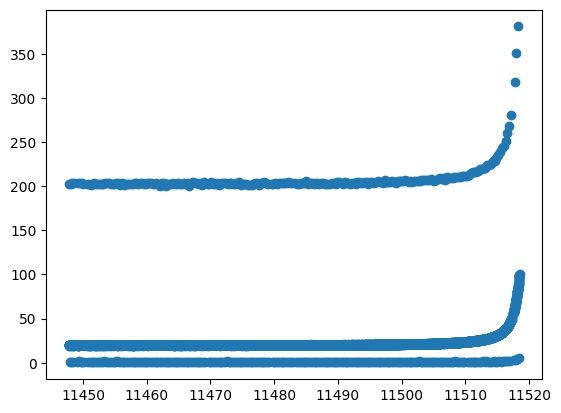

In [10]:
event_obs_season1 = event_obs.loc[event_obs['bjd']-2450000 < 11550]
plt.scatter(event_obs_season1['bjd']-2450000, event_obs_season1['flux_uJy'], label='all')
#plt.scatter(meta_df_1s2l_season1['bjd']-2450000, meta_df_1s2l_season1['flux_uJy'], label='Season 1')
#plt.xlim([event_obs['bjd'].iloc[0]-2450000, 11550])
plt.show()

### MCMC

Specifically, imma try nested sampling

In [11]:
%pip install dynesty


  Using cached dynesty-3.2.0-py3-none-any.whl.metadata (3.6 kB)
Using cached dynesty-3.2.0-py3-none-any.whl (110 kB)

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [12]:
import VBMicrolensing
import dynesty
from dynesty import utils as dyfunc
import corner

In [13]:
event_obs_season1_filt = event_obs_season1.loc[event_obs_season1['filt'] == 'F146']
event_obs_season1_filt

,event_id,name,bjd,filt,flux_uJy,flux_err_uJy,t0lens1,tE_helio,tE_ref,u0lens1,rho,Planet_s,Planet_q,alpha,sim_label
0,306462,RMDC26_306462,2.461448e+06,F146,20.007252,0.160903,2.461519e+06,22.465055,21.431235,0.027488,0.001727,0.887598,0.000044,55.382398,RMDC26_1S2L_ML
1,306462,RMDC26_306462,2.461448e+06,F146,19.659009,0.160903,2.461519e+06,22.465055,21.431235,0.027488,0.001727,0.887598,0.000044,55.382398,RMDC26_1S2L_ML
3,306462,RMDC26_306462,2.461448e+06,F146,19.663180,0.160903,2.461519e+06,22.465055,21.431235,0.027488,0.001727,0.887598,0.000044,55.382398,RMDC26_1S2L_ML
4,306462,RMDC26_306462,2.461448e+06,F146,19.876922,0.160903,2.461519e+06,22.465055,21.431235,0.027488,0.001727,0.887598,0.000044,55.382398,RMDC26_1S2L_ML
5,306462,RMDC26_306462,2.461448e+06,F146,19.607920,0.160903,2.461519e+06,22.465055,21.431235,0.027488,0.001727,0.887598,0.000044,55.382398,RMDC26_1S2L_ML
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8176,306462,RMDC26_306462,2.461518e+06,F146,98.156896,0.275986,2.461519e+06,22.465055,21.431235,0.027488,0.001727,0.887598,0.000044,55.382398,RMDC26_1S2L_ML
8177,306462,RMDC26_306462,2.461518e+06,F146,98.582814,0.276501,2.461519e+06,22.465055,21.431235,0.027488,0.001727,0.887598,0.000044,55.382398,RMDC26_1S2L_ML
8178,306462,RMDC26_306462,2.461518e+06,F146,99.507639,0.276996,2.461519e+06,22.465055,21.431235,0.027488,0.001727,0.887598,0.000044,55.382398,RMDC26_1S2L_ML
8179,306462,RMDC26_306462,2.461518e+06,F146,99.668725,0.277474,2.461519e+06,22.465055,21.431235,0.027488,0.001727,0.887598,0.000044,55.382398,RMDC26_1S2L_ML


In [14]:
# Courtesy of Amber Malpas's Data Challenge tutorial: https://github.com/rges-pit/data-challenge-notebooks/blob/main/AAS%20Workshop/Session%20C%3A%20Binary%20Lens/Fitting_Binary_Lenses.ipynb
"""
My changes:
- in log_prior(): added 45 days after t.max() because I defined Season 1 events to go up to 30 days after its end
"""

def get_mag(x0, p, t):
    '''
    Get the magnification curve for a given model and parameters.

    Parameters
    ----------
    x0: np.ndarray with initial parameters (t0, tE, u0, rho, s, q, alpha)
    p: list[str] with parameter names
    t: np.ndarray with data epochs

    Returns
    -------
    mag: np.ndarray with magnification curve
    '''
    # We will use the VBMicrolensing package to calculate magnifications for different source positions.
    VBM = VBMicrolensing.VBMicrolensing()
     #create a dictionary of parameters
    params = dict(zip(p, x0))
    paramsc = params.copy()
    tau = (t - paramsc['t0']) / paramsc['tE']
    # Single lens model
    if len(p) < 7 :
        ul = np.sqrt(tau**2 + paramsc['u0']**2)
        if 'logrho' in paramsc.keys():
            paramsc['rho'] = 10**(paramsc['logrho'])
        mag = np.array([VBM.ESPLMag2(u, paramsc['rho']) for u in ul])
    # Binary lens model
    elif len(p) >= 7:
        salpha = np.sin(np.radians(paramsc['alpha']))
        calpha = np.cos(np.radians(paramsc['alpha']))
        xs = -paramsc['u0'] * salpha + tau * calpha
        ys = paramsc['u0'] * calpha + tau * salpha
        if 'logs' in paramsc.keys():
            paramsc['s'] = 10**(paramsc['logs'])
        if 'logq' in paramsc.keys():
            paramsc['q'] = 10**(paramsc['logq'])
        if 'logrho' in paramsc.keys():
            paramsc['rho'] = 10**(paramsc['logrho'])
        mag = np.array([VBM.BinaryMag2(paramsc['s'], paramsc['q'], xs[i], ys[i], paramsc['rho']) for i in range(len(ys))])
    return mag

def calc_Fs(modelmag: np.ndarray, f: np.ndarray, sig2: np.ndarray) -> tuple[float, float]:
    '''
    Solves for the flux parameters for a given model using least squares.

    Parameters
    ----------
    model : np.ndarray
        Model magnification curve.
    f : np.ndarray
        Observed flux values.
    sig2 : np.ndarray
        Flux errors.

    Returns
    -------
    FS : float
        Source flux.
    FB : float
        Blend flux.
    '''

    """
    Solves for FS, FB by weighted least squares with FB >= 0 using lsq_linear.
    """
    modelmag = np.asarray(modelmag, float).ravel()
    f = np.asarray(f, float).ravel()
    sig2 = np.asarray(sig2, float).ravel()

    w = 1.0 / np.sqrt(sig2)
    A = np.column_stack([modelmag, np.ones_like(modelmag)])
    Aw = A * w.reshape(-1, 1)
    bw = f * w

    res = lsq_linear(Aw, bw)
    FS, FB = res.x
    return float(FS), float(FB)
    
def chi2(x0: np.ndarray, p: list, t: np.ndarray, f: np.ndarray, sig: np.ndarray) -> float:
    '''
    Calculates the chi squared value for a given model and parameters.

    Parameters
    ----------
    x0 : np.ndarray
        Initial parameters.
    p : List[str]
        List of parameter names.
    t : np.ndarray
        Data epochs.
    f : np.ndarray
        Observed flux values.
    sig : np.ndarray
        Flux errors.

    Returns
    -------
    chi2 : float
        Chi squared value.
    '''
    mag = get_mag(x0, p, t)
    FS, FB = calc_Fs(mag, f, sig**2)
    model = FS * mag + FB

    chi2_value = np.sum((f - model)**2 / sig**2)
    return chi2_value
    
# Define the log prior function - used to set bounds on parameters
def log_prior(x0, p, t, bounds: dict | None = None):
    ''' bounds on parameters

    Parameters
    ----------
    x0 : np.ndarray
        Parameter vector (e.g., t0, tE, u0, rho, ...)
    p : list[str]
        Corresponding parameter names
    t : np.ndarray
        Data epochs
    bounds : dict | None, optional
        Optional map of parameter name -> (min, max). If None, use defaults.
    '''

    default_bounds = {'t0': (t.min(), t.max()+45), 'tE': (0.1, t.max()+45-t.min()), 'u0': (-10.0, 10.0), 'rho': (1e-5, 1.0), 's': (1e-2, 20.0), 'q': (1e-7, 1.0), 'alpha': (0.0, 360.0), 'logs': (-2, 2), 'logq': (-7, 0), 'logrho': (-5, 0)}
    bounds_map = default_bounds.copy()
    if bounds is not None:
        bounds_map.update({k: tuple(v) for k, v in bounds.items() if k in bounds_map})

    for index, key in enumerate(p):
        lower, upper = bounds_map[key]
        if x0[index] < lower or x0[index] > upper:
            return -np.inf
    return 0.
        
#Calculate the log likelihood using the chi2 function
def log_likelihood(x0, p, t, f, sig):
    '''calculating chi2'''
    ll = -1./2. * chi2(x0, p, t, f, sig)
    return ll
    
#Return the log probability by adding the log prior and log likelihood
def log_probability(x0, p, t, f, sig, bounds: dict | None = None):
    lp = log_prior(x0, p, t, bounds=bounds)
    if not np.isfinite(lp):
        return -np.inf
    return lp + log_likelihood(x0, p, t, f, sig)

# for dynesty
def bounds_map(bjd, bounds=None):
    bm = {"t0": (bjd.min(), bjd.max()+45), "tE": (0.1, bjd.max() - bjd.min()), # allow t0 to roam slightly off-screen
          "u0": (-10.0, 10.0), "alpha": (0.0, 360.0),
          "logs": (-2, 2), "logq": (-7, 0), "logrho": (-5, 0)}
    if bounds:
        bm.update({k: tuple(v) for k, v in bounds.items() if k in bm})
    return bm
    

In [15]:
# transform params to VBMicrolensing-friendly params
ln_s = np.log(s)
ln_q = np.log(q)
ln_rho = np.log(rho)
ln_tE = np.log(tE)
sig_ln_s = s_err/s
sig_ln_q = q_err/q
sig_ln_rho = rho_err/rho
sig_ln_tE = tE_err/tE

# transform unit cube to prior; get_mag() accepts inputs in the following order: (t0, tE, u0, rho, s, q, alpha)
best = np.array([ln_s, ln_q, u0, alpha, ln_rho, ln_tE, t0])
sig  = np.array([sig_ln_s, sig_ln_q, u0_err, alpha_err, sig_ln_rho, sig_ln_tE, t0_err])

# grab actual data
event_obs_season1_filt['bjd-2450000'] = event_obs_season1_filt['bjd'] - 2450000
bjd = event_obs_season1_filt["bjd-2450000"].to_numpy(float)#.tolist()   
flux = event_obs_season1_filt["flux_uJy"].to_numpy(float)
flux_err = event_obs_season1_filt["flux_err_uJy"].to_numpy(float)

/tmp/ipykernel_611/2351589699.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  event_obs_season1_filt['bjd-2450000'] = event_obs_season1_filt['bjd'] - 2450000


In [ ]:
import emcee, corner
from multiprocess import Pool, cpu_count

# best fit params from RTModel
x0 = np.array([t0, tE, u0, rho, s, q, np.degrees(alpha)])
param_names = ["t0", "tE", "u0", "rho", "s", "q", "alpha"]
bounds = None   # or e.g. {"t0": (x0[0]-x0[1], x0[0]+x0[1]), "tE": (x0[1]-20, x0[1]+20)}

ndim, nwalkers, nsteps = len(param_names), 100, 20000
scales = np.array([1e-2, 1e-2, 1e-2, 1e-2, 1e-2, 1e-2, 1e-1])  # per-parameter ball size
rng = np.random.default_rng(46)

# Initial ball around x0; x0 itself must lie inside the bounds or this loops forever
p0 = x0 + scales * rng.standard_normal((nwalkers, ndim))
for k in range(nwalkers):
    while not np.isfinite(log_prior(p0[k], param_names, bjd, bounds)):
        p0[k] = x0 + scales * rng.standard_normal(ndim)

with Pool(cpu_count() - 1) as pool:
    sampler = emcee.EnsembleSampler(
        nwalkers, ndim, log_probability,
        args=(param_names, bjd, flux, flux_err, bounds), 
        pool=pool)
    sampler.run_mcmc(p0, nsteps, progress=True)

tau = sampler.get_autocorr_time(tol=0)
flat = sampler.get_chain(discard=int(5 * tau.max()), thin=max(1, int(tau.min() / 2)), flat=True)
fig = corner.corner(flat, labels=param_names, quantiles=[0.16, 0.5, 0.84], show_titles=True)

In [ ]:
tau = sampler.get_autocorr_time(tol=0)
flat = sampler.get_chain(discard=int(5 * tau.max()), thin=max(1, int(tau.min() / 2)), flat=True)
fig = corner.corner(flat, labels=param_names, quantiles=[0.16, 0.5, 0.84], show_titles=True)

#### Dynesty

 48%|████▊     | 6253/13066 [1:10:04<2:15:43,  1.20s/it, bound: 58 | nc: 63 | ncall: 300235 | eff(%):  2.083 | loglstar: -17597.069 | logz: -17616.470 | dlogz: 12974.415 >  1.000]IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)

 19%|█▉        | 10315/54322 [2:35:39<14:18:36,  1.17s/it, bound: 107 | nc: 53 | ncall: 545288 | eff(%):  1.892 | loglstar: -4671.607 | logz: -4695.712 | dlogz: 537.238 >  1.000]IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)

100%|██

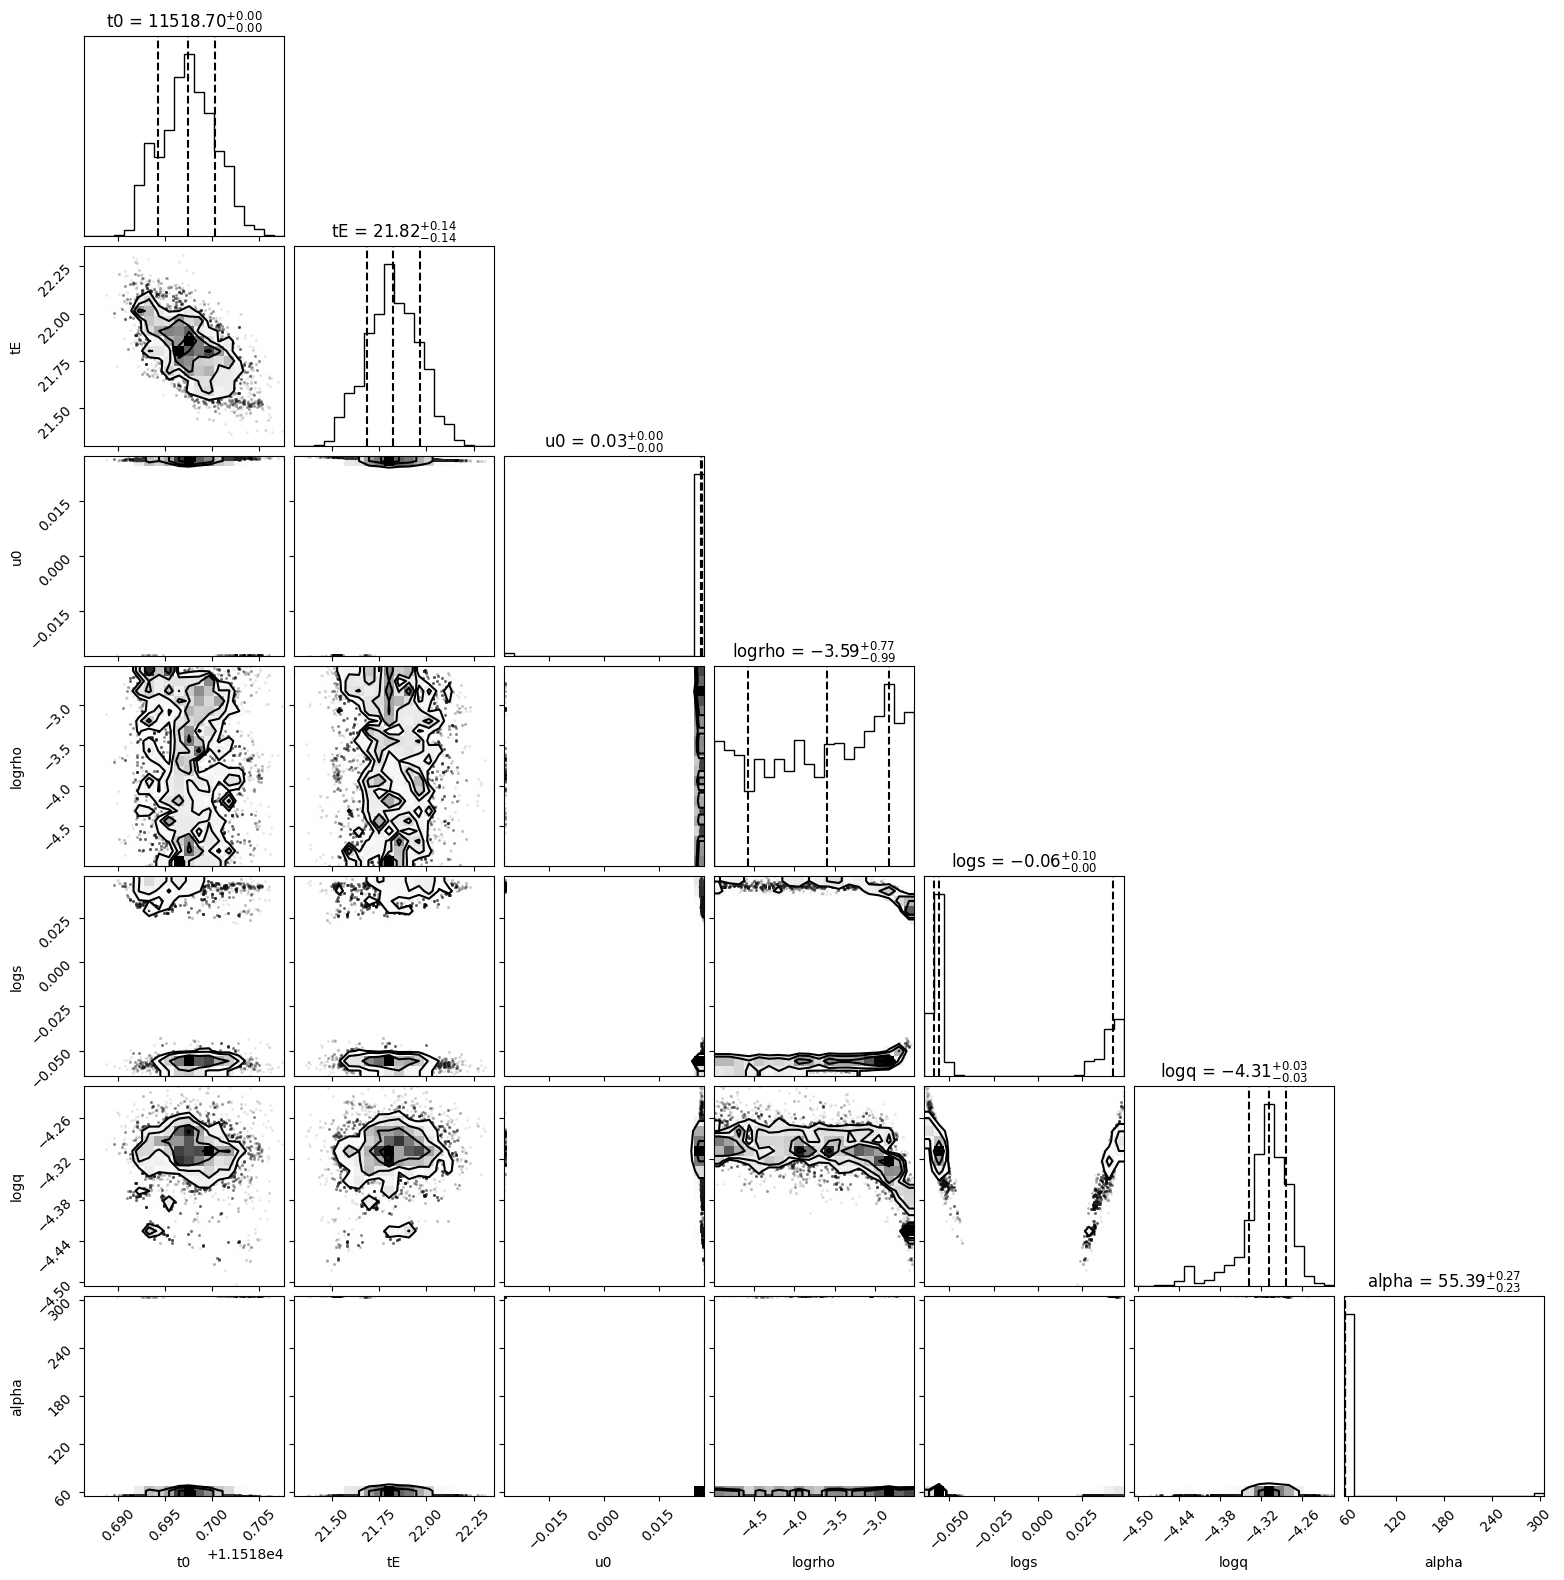

In [22]:
import dynesty
from dynesty import utils as dyfunc

labels = ["t0", "tE", "u0", "logrho", "logs", "logq", "alpha"]
bounds = None 
def bounds_map(bjd, bounds=None):
    bm = {"t0": (bjd.min(), bjd.max()+45), "tE": (0.1, bjd.max() - bjd.min()), # allow t0 to roam slightly off-screen
          "u0": (-10.0, 10.0), "alpha": (0.0, 360.0),
          "logs": (-1, 1), "logq": (-7, -2), "logrho": (-5, 0)}
    if bounds:
        bm.update({k: tuple(v) for k, v in bounds.items() if k in bm})
    return bm
    
bm = bounds_map(bjd, bounds)
lo = np.array([bm[k][0] for k in labels])
hi = np.array([bm[k][1] for k in labels])

def prior_transform(u, lo, hi):
    return lo + u * (hi - lo)

def loglike(theta, labels, bjd, flux, flux_err):
    ll = log_likelihood(theta, labels, bjd, flux, flux_err)
    return ll if np.isfinite(ll) else -np.inf

sampler = dynesty.NestedSampler(
    loglike, prior_transform, len(labels),
    logl_args=(labels, bjd, flux, flux_err), ptform_args=(lo, hi),
    nlive=500, bound="multi", sample="rslice",
    periodic=[labels.index("alpha")] # cuz alpha is circle
)
sampler.run_nested(dlogz=1.) # used to be 0.1
res = sampler.results

w  = np.exp(res.logwt - res.logz[-1])
eq = dyfunc.resample_equal(res.samples, w)
fig = corner.corner(eq, labels=labels, quantiles=[0.16, 0.5, 0.84], show_titles=True)